# Projeto Aplicado I - Olist

Henrique Fernandes Corradini - RA 1077304 - Tecnologia em Banco de Dados.

Etapas 1 e 2. Pergunta: como prazo, atraso e frete se associam às avaliações? Fonte: [Olist / Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), versão 2, adquirida em 05/10/2026. Uso educacional, CC BY-NC-SA 4.0.

Execute `acquire.py` primeiro, instale `requirements.txt` em seu ambiente e abra este notebook com a pasta atual apontando para o repositório. Dados são históricos, não representam a operação atual. UM designa a unidade monetária original; a moeda não foi explicitamente confirmada nos metadados acessados. Não inferir causalidade.

## Bibliotecas e diretórios
Python, pandas e NumPy para tabelas e cálculo; Matplotlib para gráficos. A pasta temporária de dependências é opcional fora do ambiente original.

In [1]:
# Ambiente e diretórios de saída
from pathlib import Path
import json
import sys
import hashlib
import platform
import numpy as np
import pandas as pd

ROOT = Path.cwd()
assert (ROOT / 'data').is_dir(), 'Abra o notebook a partir da pasta que contém data/'
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

OUT = ROOT / 'analysis'
OUT.mkdir(exist_ok=True)
FIG = OUT / 'figures'
FIG.mkdir(exist_ok=True)



## Funções de integração e verificação mínima
A checagem inclui pedidos com vários itens e pagamentos, duas avaliações, ausência de entrega e entrega no dia previsto. As funções são comuns ao notebook e ao script.

In [2]:
# Regras comuns de integração, datas e avaliação
def latest_reviews(reviews):
    return reviews.sort_values(
        ['order_id', 'review_answer_timestamp', 'review_creation_date', 'review_id'],
        na_position='first', kind='stable'
    ).drop_duplicates('order_id', keep='last')

def assemble(orders, customers, items, payments, reviews):
    assert orders.order_id.notna().all() and orders.order_id.is_unique
    assert customers.customer_id.notna().all() and customers.customer_id.is_unique
    item = items.groupby('order_id', sort=False).agg(
        value_items=('price', 'sum'), freight=('freight_value', 'sum'),
        item_count=('order_item_id', 'size'))
    pay = payments.groupby('order_id', sort=False).payment_value.sum(min_count=1).rename('payment_total')
    result = orders.merge(customers, on='customer_id', how='left', validate='many_to_one', indicator=True)
    assert (result['_merge'] == 'both').all()
    result = result.drop(columns='_merge').merge(item, on='order_id', how='left', validate='one_to_one')
    result = result.merge(pay, on='order_id', how='left', validate='one_to_one')
    result = result.merge(latest_reviews(reviews)[['order_id', 'review_score']],
                          on='order_id', how='left', validate='one_to_one')
    assert len(result) == len(orders) and result.order_id.is_unique
    assert np.isclose(result.value_items.sum(), items.price.sum())
    assert np.isclose(result.freight.sum(), items.freight_value.sum())
    assert np.isclose(result.payment_total.sum(), payments.payment_value.sum())
    purchase = result.order_purchase_timestamp
    actual = result.order_delivered_customer_date
    expected = result.order_estimated_delivery_date
    valid = result.order_status.eq('delivered') & purchase.notna() & actual.notna() & expected.notna()
    valid &= actual.ge(purchase) & expected.ge(purchase)
    result['valid_logistics'] = valid
    result['delivery_days'] = ((actual - purchase).dt.total_seconds() / 86400).where(valid)
    result['delay_days'] = ((actual.dt.normalize() - expected.dt.normalize()).dt.days).where(valid)
    result['late'] = result.delay_days.gt(0).where(valid).astype('boolean')
    result['freight_ratio'] = (100 * result.freight / result.value_items).where(result.value_items.gt(0))
    result['review_score'] = result.review_score.where(result.review_score.isin([1, 2, 3, 4, 5]))
    return result

def self_check():
    orders = pd.DataFrame({
        'order_id': ['a', 'b'], 'customer_id': ['x', 'y'], 'order_status': ['delivered', 'delivered'],
        'order_purchase_timestamp': pd.to_datetime(['2020-01-01', '2020-01-01']),
        'order_delivered_customer_date': pd.to_datetime(['2020-01-03 20:00', None]),
        'order_estimated_delivery_date': pd.to_datetime(['2020-01-03', '2020-01-03'])})
    customers = pd.DataFrame({'customer_id': ['x', 'y']})
    items = pd.DataFrame({'order_id': ['a', 'a', 'b'], 'order_item_id': [1, 2, 1],
                          'price': [10., 20., 5.], 'freight_value': [2., 3., 1.]})
    payments = pd.DataFrame({'order_id': ['a', 'a', 'b'], 'payment_value': [15., 20., 6.]})
    reviews = pd.DataFrame({'order_id': ['a', 'a'], 'review_id': ['r1', 'r2'], 'review_score': [1, 5],
                            'review_creation_date': pd.to_datetime(['2020-01-03', '2020-01-04']),
                            'review_answer_timestamp': pd.to_datetime(['2020-01-04', '2020-01-05'])})
    result = assemble(orders, customers, items, payments, reviews).set_index('order_id')
    assert result.loc['a', 'value_items'] == 30 and result.loc['a', 'payment_total'] == 35
    assert result.loc['a', 'review_score'] == 5 and result.loc['a', 'delay_days'] == 0
    assert not result.loc['a', 'late'] and pd.isna(result.loc['b', 'late'])
    assert pd.isna(result.loc['b', 'delivery_days'])
    return 'PASS: agregação, pagamentos múltiplos, avaliação mais recente, data ausente e entrega no dia previsto'



## Aquisição local e inventário
Os dados originais são preservados. Cada arquivo tem granularidade própria; inventariar linhas e colunas precede a integração.

In [3]:
# Aquisição local e inventário
checks = [self_check()]
raw = {}
inventory = []
chosen = ['orders', 'customers', 'order_items', 'order_payments', 'order_reviews']
for path in sorted((ROOT / 'data').glob('*.csv')):
    key = path.stem.removeprefix('olist_').removesuffix('_dataset')
    if key in chosen:
        frame = pd.read_csv(path, dtype={c: 'string' for c in pd.read_csv(path, nrows=0).columns
                                       if c.endswith('_id') or 'zip_code' in c})
        raw[key] = frame
        n, cols = frame.shape
    else:
        cols = len(pd.read_csv(path, nrows=0).columns)
        n = sum(len(chunk) for chunk in pd.read_csv(path, chunksize=100000))
    inventory.append({'file': path.name, 'rows': n, 'cols': cols, 'used': key in chosen,
                      'sha256': hashlib.sha256(path.read_bytes()).hexdigest()})


## Perfil dos atributos e auditoria
NAs não são zero. A auditoria valida chaves, categorias de nota, cronologia e valores. Identificadores não recebem estatísticas quantitativas artificiais.

In [4]:
# Perfil dos atributos e auditoria
missing = {k: {c: int(v) for c, v in d.isna().sum().items()} for k, d in raw.items()}
duplicates = {k: int(d.duplicated().sum()) for k, d in raw.items()}
date_errors = {}
for k in ['orders', 'order_items', 'order_reviews']:
    for c in raw[k]:
        if 'date' in c or 'timestamp' in c or c == 'order_approved_at':
            original = raw[k][c]
            raw[k][c] = pd.to_datetime(original, errors='coerce')
            date_errors[k + '.' + c] = int((original.notna() & raw[k][c].isna()).sum())
orders, customers, items, payments, reviews = [raw[k] for k in chosen]
# Perfil de todas as colunas: IDs e categorias não recebem médias artificiais.
profile = {}
for name, frame in raw.items():
    profile[name] = {}
    for col, series in frame.items():
        valid = series.dropna()
        row = {'type': str(series.dtype), 'n': len(series), 'non_missing': len(valid),
               'missing': int(series.isna().sum()), 'distinct': int(series.nunique()),
               'top': {} if col.endswith('_id') or 'zip_code' in col or 'review_comment' in col
               else {str(k): int(v) for k,v in series.value_counts().head(3).items()}}
        if pd.api.types.is_datetime64_any_dtype(series):
            row.update(min=str(valid.min()), max=str(valid.max()))
        elif pd.api.types.is_numeric_dtype(series):
            row.update(min=valid.min(), max=valid.max())
            if col in ['price','freight_value','payment_value','payment_installments']:
                q1,q3=valid.quantile([.25,.75])
                row.update(mean=valid.mean(), median=valid.median(), var=valid.var(ddof=1),
                           std=valid.std(ddof=1), outliers=int(((valid<q1-1.5*(q3-q1))|
                                                            (valid>q3+1.5*(q3-q1))).sum()))
        profile[name][col] = row
anomalies = {
    'negative_price': int(items.price.lt(0).sum()),
    'negative_freight': int(items.freight_value.lt(0).sum()),
    'negative_payment': int(payments.payment_value.lt(0).sum()),
    'zero_price': int(items.price.eq(0).sum()),
    'zero_freight': int(items.freight_value.eq(0).sum()),
    'zero_payment': int(payments.payment_value.eq(0).sum()),
    'invalid_review': int((reviews.review_score.notna() & ~reviews.review_score.isin([1,2,3,4,5])).sum()),
    'delivered_before_purchase': int(orders.order_delivered_customer_date.lt(orders.order_purchase_timestamp).sum()),
    'estimate_before_purchase': int(orders.order_estimated_delivery_date.lt(orders.order_purchase_timestamp).sum()),
    'approved_before_purchase': int(orders.order_approved_at.lt(orders.order_purchase_timestamp).sum()),
    'carrier_before_purchase': int(orders.order_delivered_carrier_date.lt(orders.order_purchase_timestamp).sum()),
    'delivery_before_carrier': int(orders.order_delivered_customer_date.lt(orders.order_delivered_carrier_date).sum()),
    'duplicated_item_key': int(items.duplicated(['order_id','order_item_id']).sum()),
    'duplicated_payment_key': int(payments.duplicated(['order_id','payment_sequential']).sum()),
    'repeated_review_ids': int(reviews.review_id.duplicated().sum()),
}
assert not any(anomalies[k] for k in ['negative_price','negative_freight','negative_payment','invalid_review',
                                     'duplicated_item_key','duplicated_payment_key'])
assert not any(duplicates.values())
for name, frame in [('items',items),('payments',payments),('reviews',reviews)]:
    assert frame.order_id.isin(orders.order_id).all(), 'Unmatched order: ' + name


## Integração e variáveis derivadas
Agregue itens e pagamentos antes de juntá-los. A avaliação mais recente é escolhida por pedido. Entrega no mesmo dia da estimativa é pontual.

In [5]:
# Integração e variáveis derivadas
repeat_reviews = reviews.groupby('order_id').size()
repeats = {'orders': int(repeat_reviews.gt(1).sum()),
           'removed_rows': int(len(reviews)-len(repeat_reviews)),
           'rows_in_affected_orders': int(repeat_reviews[repeat_reviews.gt(1)].sum())}
selected = latest_reviews(reviews)
d = assemble(orders, customers, items, payments, reviews)
d.to_csv(OUT / 'orders_analytic.csv', index=False, encoding='utf-8')
logistics = d[d.valid_logistics].copy()
reviewed = logistics[logistics.review_score.notna()].copy()


## Medidas descritivas e correlações
Use variância amostral e quartis interpolados. Outliers são identificados, não removidos. Spearman é Pearson dos postos médios com tratamento de empates.

In [6]:
# Medidas descritivas e correlações
stats = {}
measures = ['delivery_days','delay_days','value_items','freight','payment_total','freight_ratio']
for v in measures:
    s = d[v].dropna()
    q1,q3=s.quantile([.25,.75])
    modes=s.mode()
    stats[v] = {'n':len(s),'mean':s.mean(),'median':s.median(),'mode':float(modes.iloc[0]),
                'mode_count':int(s.eq(modes.iloc[0]).sum()),'mode_ties':len(modes),
                'min':s.min(),'q1':q1,'q3':q3,'p10':s.quantile(.1),'p90':s.quantile(.9),'p95':s.quantile(.95),
                'max':s.max(),'range':s.max()-s.min(),'var':s.var(ddof=1),'std':s.std(ddof=1),
                'cv_pct':100*s.std(ddof=1)/s.mean() if v!='delay_days' and s.mean()>0 else None,
                'iqr':q3-q1,'lower_fence':q1-1.5*(q3-q1),'upper_fence':q3+1.5*(q3-q1),
                'outliers':int(((s<q1-1.5*(q3-q1))|(s>q3+1.5*(q3-q1))).sum())}
groups=[]
for late, g in reviewed.groupby('late'):
    groups.append({'late':bool(late),'n':len(g),'median_review':g.review_score.median(),
                   'low_reviews':int(g.review_score.le(2).sum()),'low_pct':100*g.review_score.le(2).mean(),
                   'median_delivery':g.delivery_days.median()})
state = logistics.groupby('customer_state').agg(n=('order_id','size'),late_n=('late','sum'),
                                               median_days=('delivery_days','median'))
state['late_pct']=100*state.late_n/state.n
state=state.sort_values('late_pct',ascending=False)
state.to_csv(OUT / 'state.csv')
spearman=[]
for v in ['delivery_days','delay_days','freight','freight_ratio','value_items']:
    pair=reviewed[[v,'review_score']].dropna()
    rho=pair.rank(method='average').corr(method='pearson').iloc[0,1]
    spearman.append({'variable':v,'n':len(pair),'rho':rho})
pearson_vars=['delivery_days','delay_days','value_items','freight','payment_total','freight_ratio']
pearson=logistics[pearson_vars].corr()
pearson.to_csv(OUT / 'pearson.csv')
pair_n=logistics[pearson_vars].notna().astype(int).T.dot(logistics[pearson_vars].notna().astype(int))
pair_n.to_csv(OUT / 'pearson_n.csv')
review_freq=d.review_score.value_counts().sort_index()
monthly=d.groupby(d.order_purchase_timestamp.dt.to_period('M')).size()
monthly=monthly.reindex(pd.period_range(monthly.index.min(),monthly.index.max(),freq='M'),fill_value=0)
def save(name):
    plt.tight_layout()
    plt.savefig(FIG / (name+'.png'), dpi=180, facecolor='white')
    plt.close()


## Gráficos exploratórios
Cada gráfico responde a uma pergunta. Escalas logarítmicas são rotuladas, extremos são preservados e cada ponto do gráfico de dispersão é um pedido.

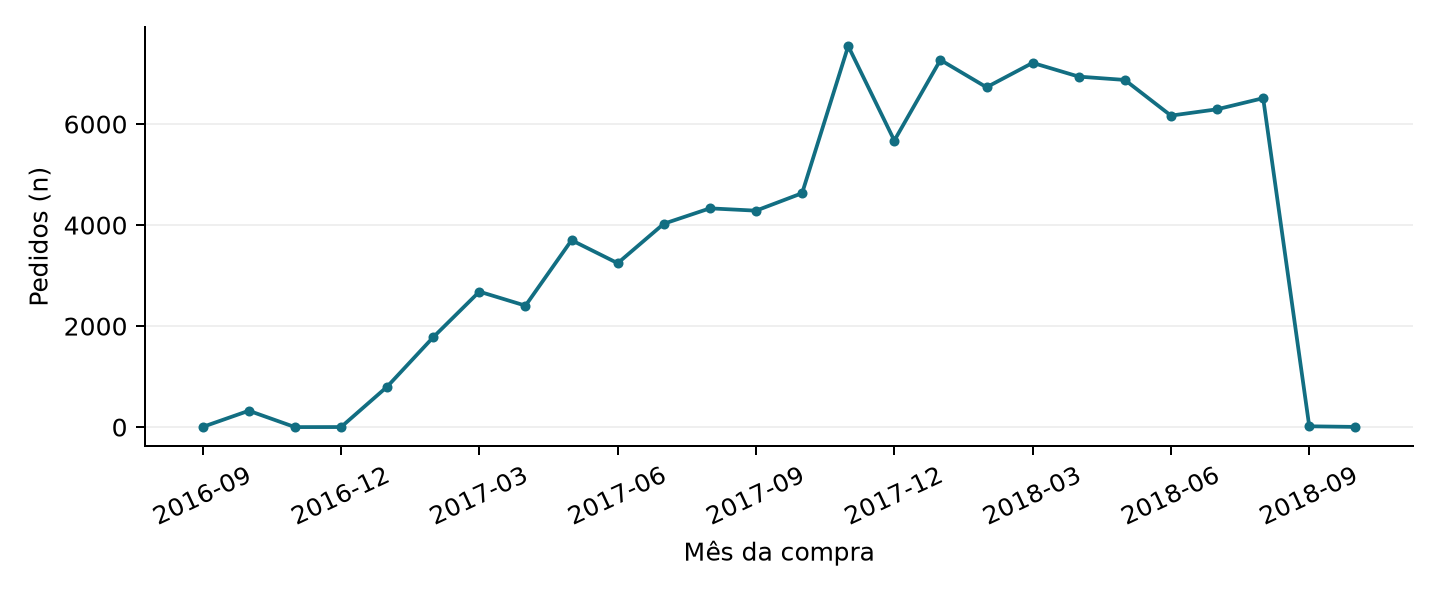

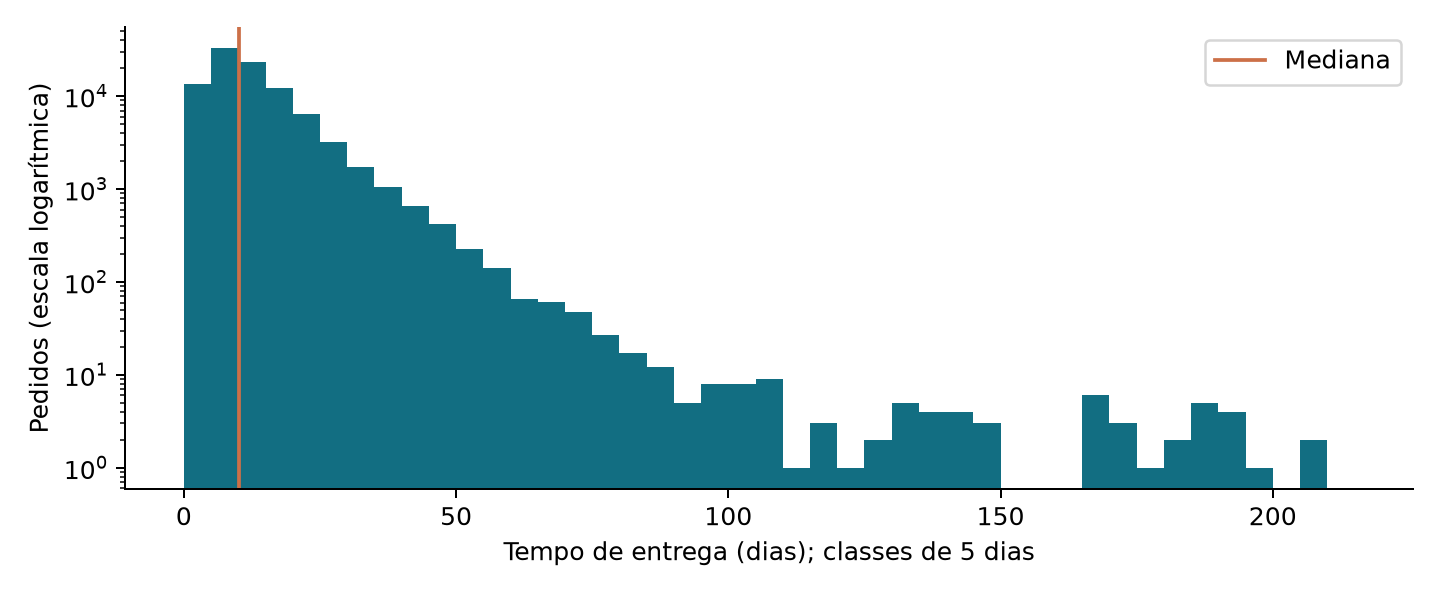

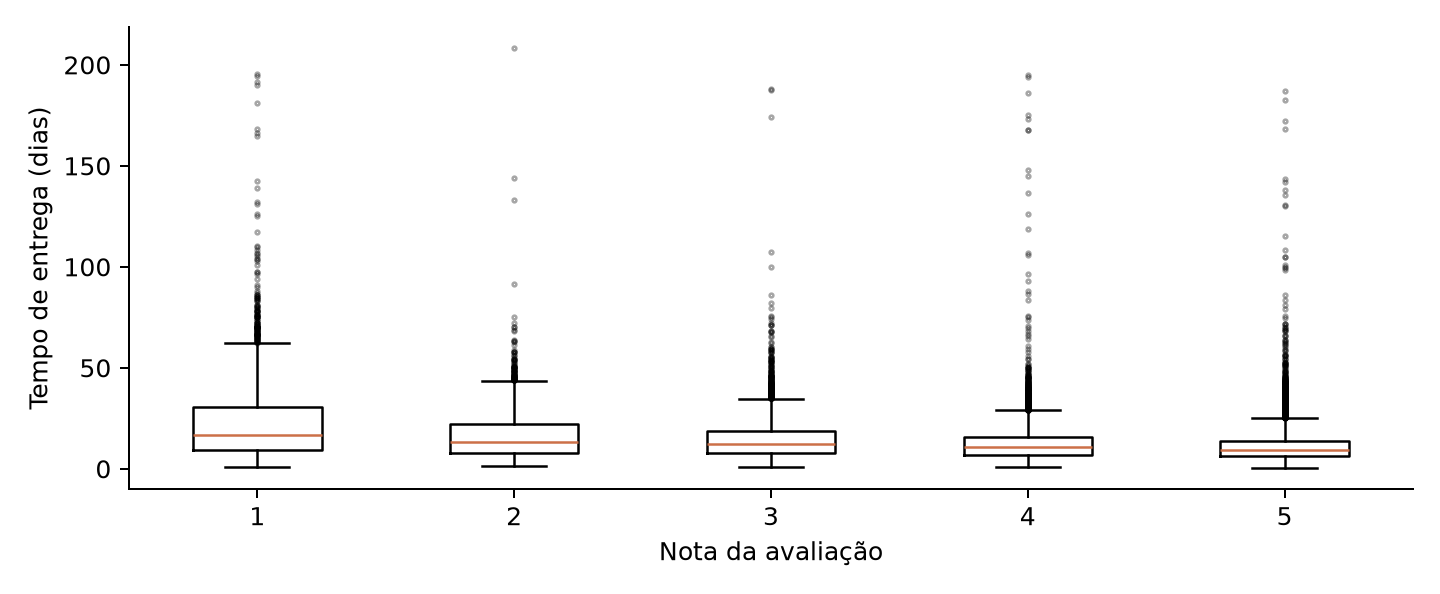

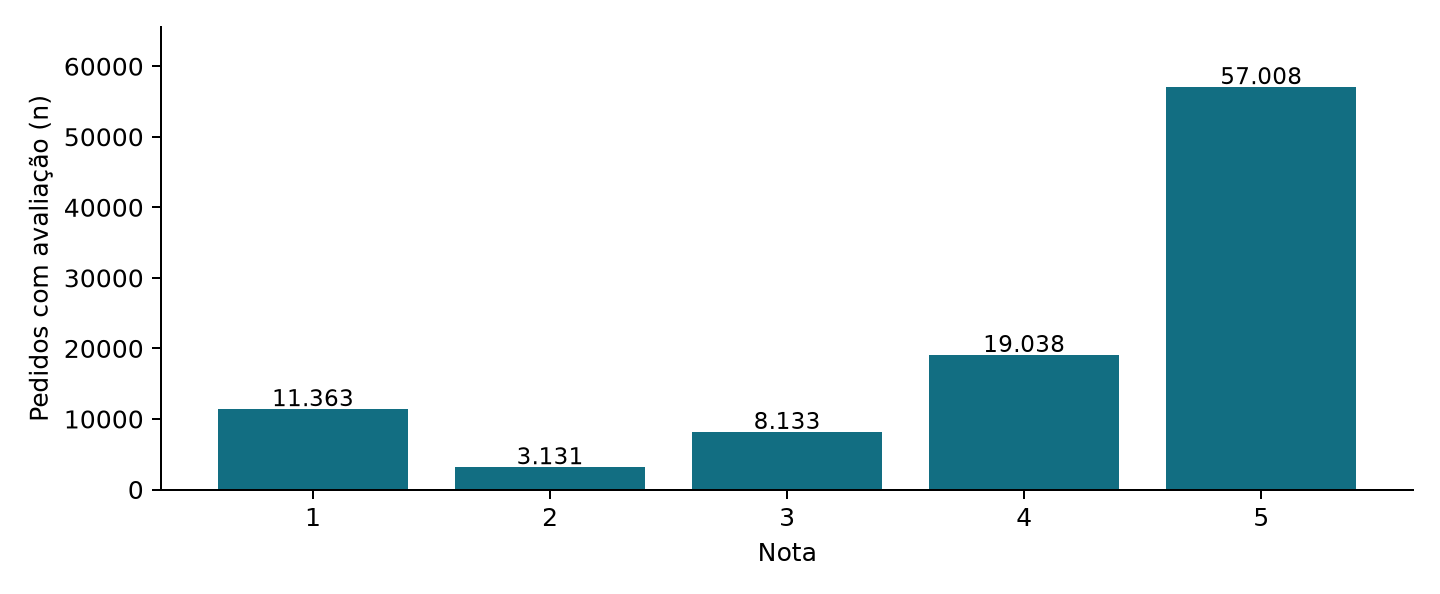

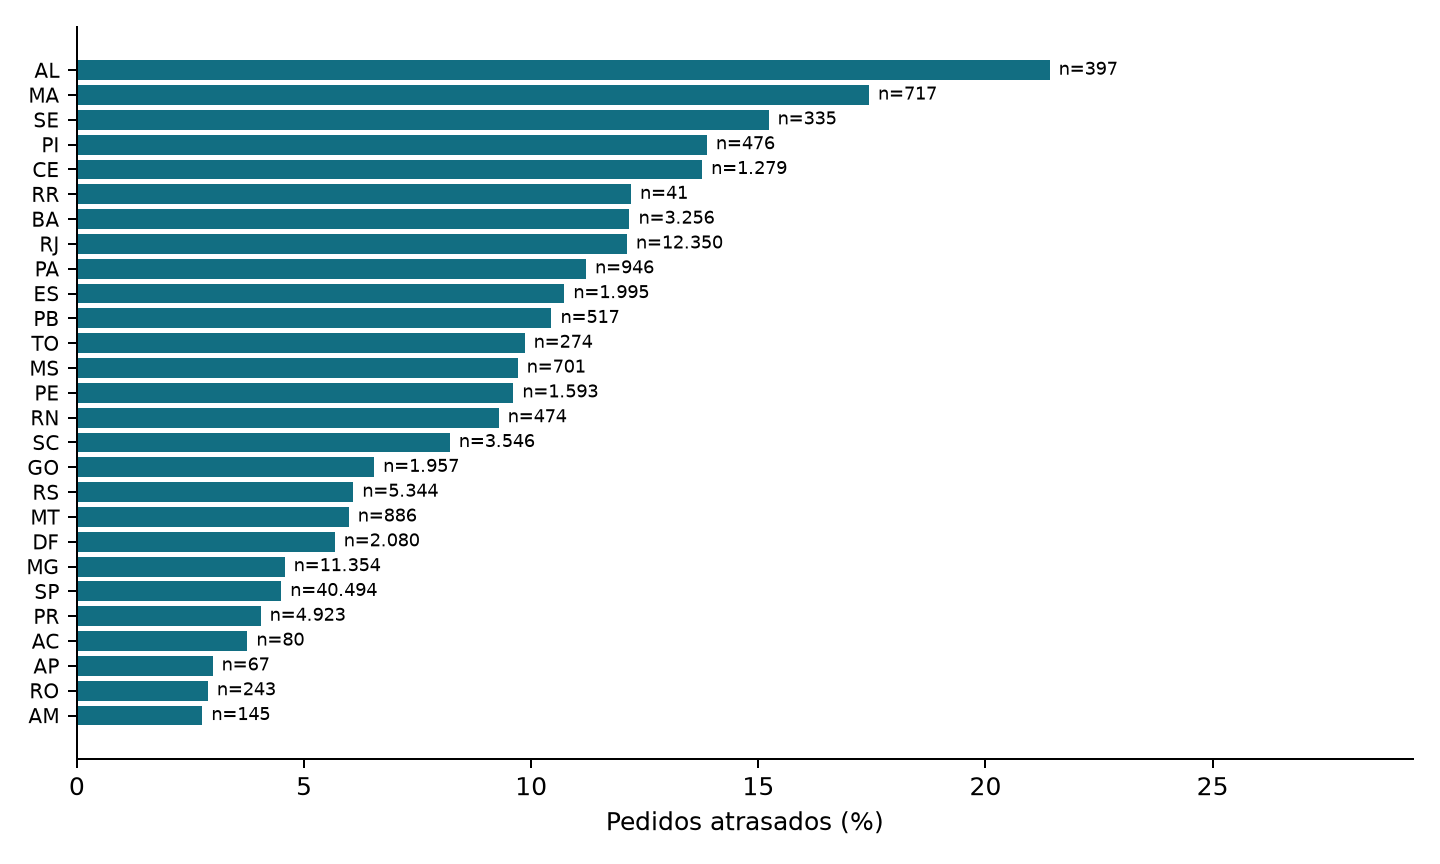

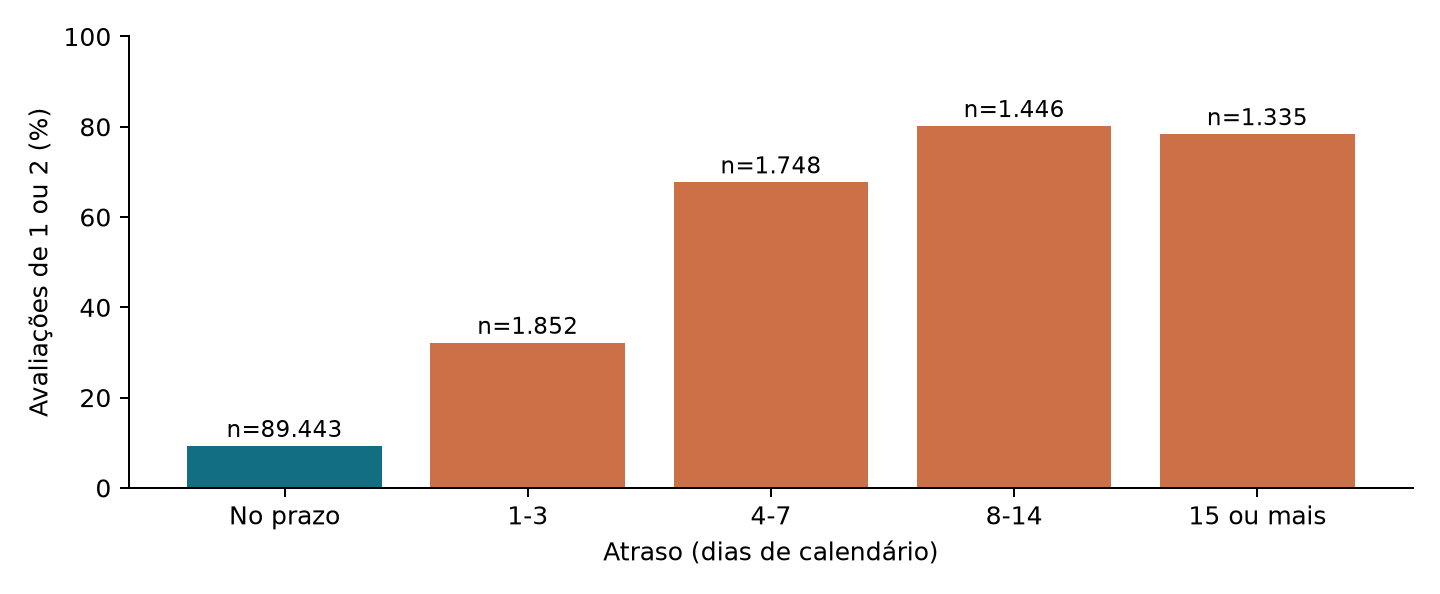

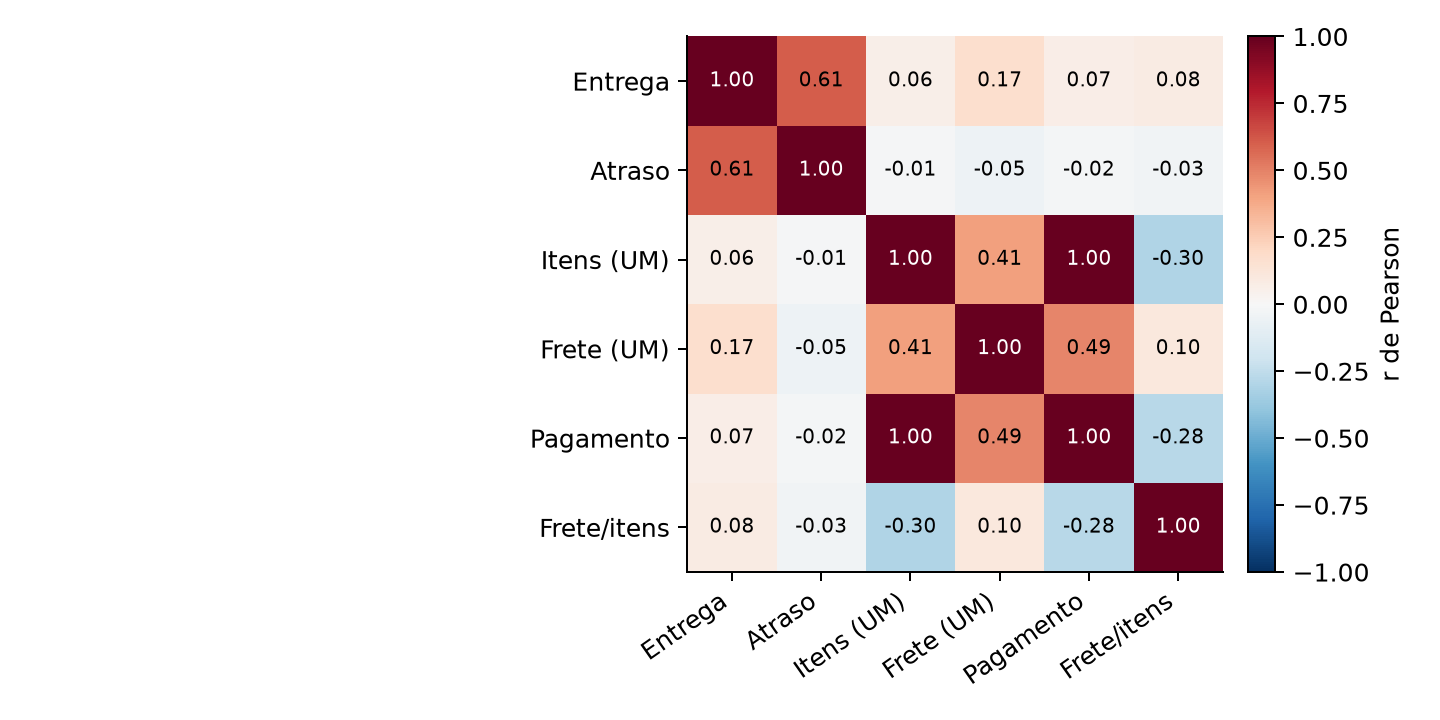

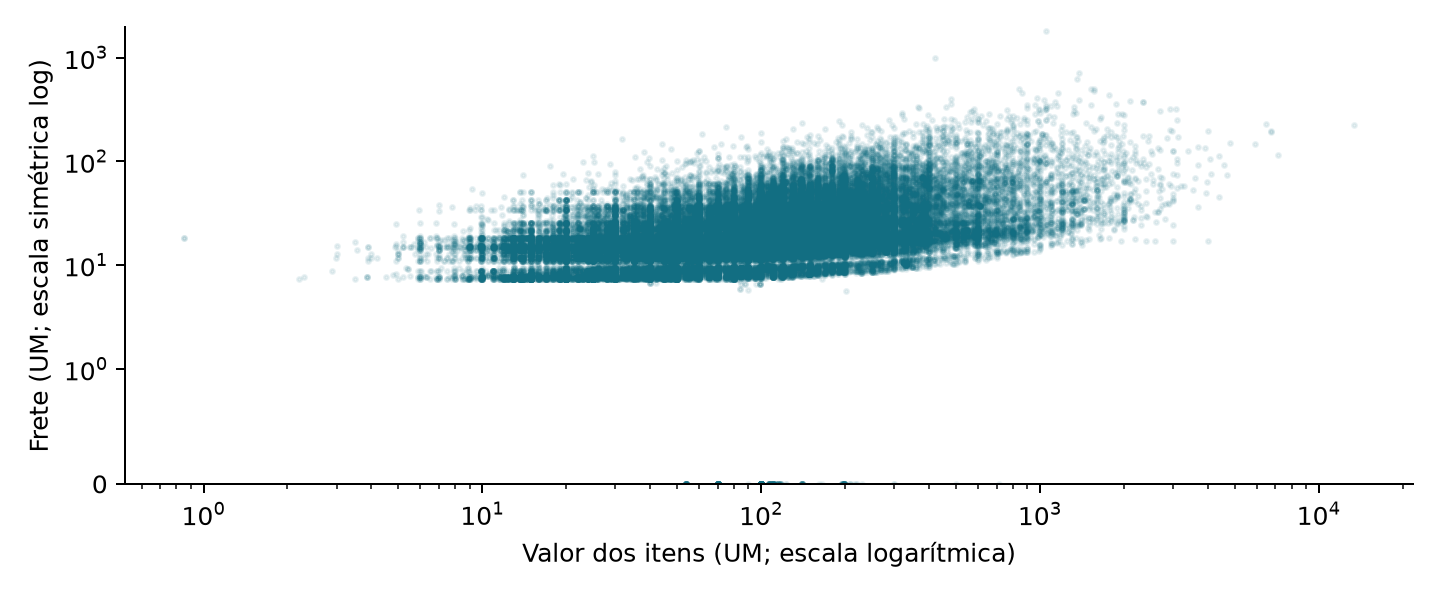

In [7]:
# Gráficos exploratórios
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig, ax=plt.subplots(figsize=(8,3.3))
ax.plot(range(len(monthly)),monthly.to_numpy(),color='#126E82',marker='o',markersize=3)
ticks=list(range(0,len(monthly),3))
ax.set_xticks(ticks,[str(monthly.index[i]) for i in ticks],rotation=25)
ax.set_ylabel('Pedidos (n)'); ax.set_xlabel('Mês da compra'); ax.grid(axis='y',alpha=.2)
save('monthly')
fig, ax=plt.subplots(figsize=(8,3.3))
counts, edges=np.histogram(logistics.delivery_days,bins=np.arange(0,216,5))
assert counts.sum()==len(logistics)
ax.stairs(counts,edges,fill=True,color='#126E82'); ax.set_yscale('log')
ax.set_ylabel('Pedidos (escala logarítmica)');ax.set_xlabel('Tempo de entrega (dias); classes de 5 dias')
ax.axvline(logistics.delivery_days.median(),color='#CC7048',label='Mediana');ax.legend()
save('distribution')
fig, ax=plt.subplots(figsize=(8,3.3))
ax.boxplot([reviewed.loc[reviewed.review_score.eq(i),'delivery_days'] for i in range(1,6)],
           tick_labels=['1','2','3','4','5'],showfliers=True,
           flierprops={'markersize':1.5,'alpha':.35},medianprops={'color':'#CC7048'})
ax.set_xlabel('Nota da avaliação');ax.set_ylabel('Tempo de entrega (dias)')
save('boxplot')
fig, ax=plt.subplots(figsize=(8,3.3))
ax.bar([str(int(i)) for i in review_freq.index],review_freq,color='#126E82')
for j,n in enumerate(review_freq):ax.text(j,n+450,f'{n:,}'.replace(',','.'),ha='center',fontsize=9)
ax.set_ylim(0,review_freq.max()*1.15);ax.set_ylabel('Pedidos com avaliação (n)');ax.set_xlabel('Nota')
save('reviews')
fig, ax=plt.subplots(figsize=(8,4.8))
st=state.sort_values('late_pct')
ax.barh(st.index,st.late_pct,color='#126E82')
ax.set_xlabel('Pedidos atrasados (%)');ax.tick_params(axis='y',labelsize=8)
for j,(_,r) in enumerate(st.iterrows()): ax.text(r.late_pct+.2,j,f'n={int(r.n):,}'.replace(',','.'),va='center',fontsize=7)
ax.set_xlim(0,st.late_pct.max()+8)
save('states')
fig, ax=plt.subplots(figsize=(8,3.3))
bins=[-np.inf,0,3,7,14,np.inf]; labels=['No prazo','1-3','4-7','8-14','15 ou mais']
bucket=pd.cut(reviewed.delay_days,bins=bins,labels=labels)
bucket_results=[]
for name in labels:
    g=reviewed[bucket.eq(name)]
    bucket_results.append({'group':name,'n':len(g),'low_pct':100*g.review_score.le(2).mean()})
ax.bar(labels,[r['low_pct'] for r in bucket_results],color=['#126E82']+['#CC7048']*4)
for i,r in enumerate(bucket_results): ax.text(i,r['low_pct']+2,f"n={r['n']:,}".replace(',','.'),ha='center',fontsize=9)
ax.set_ylim(0,100);ax.set_ylabel('Avaliações de 1 ou 2 (%)');ax.set_xlabel('Atraso (dias de calendário)')
save('delay_reviews')
fig, ax=plt.subplots(figsize=(8,4))
im=ax.imshow(pearson,vmin=-1,vmax=1,cmap='RdBu_r')
short=['Entrega','Atraso','Itens (UM)','Frete (UM)','Pagamento','Frete/itens']
ax.set_xticks(range(6),short,rotation=35,ha='right');ax.set_yticks(range(6),short)
for i in range(6):
    for j in range(6):ax.text(j,i,f'{pearson.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8,
                             color='white' if abs(pearson.iloc[i,j])>.65 else 'black')
fig.colorbar(im,ax=ax,fraction=.04,pad=.02,label='r de Pearson')
save('correlation')
fig, ax=plt.subplots(figsize=(8,3.3))
pair=logistics[['value_items','freight']].dropna()
ax.scatter(pair.value_items,pair.freight,s=3,alpha=.09,color='#126E82',rasterized=True)
ax.set_xscale('log');ax.set_yscale('symlog',linthresh=1)
ax.set_ylim(0,pair.freight.max()*1.1)
ax.set_xlabel('Valor dos itens (UM; escala logarítmica)');ax.set_ylabel('Frete (UM; escala simétrica log)')
save('scatter')


## Reconciliação e resultados finais
A reconciliação global compara agregados com suas próprias tabelas de origem. A divergência por pedido entre pagamento e itens mais frete é uma auditoria distinta.

In [8]:
# Reconciliação e resultados finais
both=d[d.value_items.notna() & d.payment_total.notna()]
mismatch=((both.value_items+both.freight-both.payment_total).abs()>.01+1e-8)
raw_selected_missing=int(selected.review_score.isna().sum())
result={
    'inventory':inventory,'profile':profile,'missing':missing,'duplicates':duplicates,'date_errors':date_errors,
    'anomalies':anomalies,'repeat_reviews':repeats,'stats':stats,'review_groups':groups,
    'states':state.reset_index().to_dict('records'),'spearman':spearman,
    'pearson':pearson.to_dict(),'pearson_n':pair_n.to_dict(),
    'review_freq':{str(int(k)):int(v) for k,v in review_freq.items()},
    'status':{str(k):int(v) for k,v in d.order_status.value_counts().items()},
    'monthly':{str(k):int(v) for k,v in monthly.items()},'delay_buckets':bucket_results,
    'counts':{'orders':len(d),'delivered_status':int(d.order_status.eq('delivered').sum()),
              'logistics':len(logistics),'logistics_reviewed':len(reviewed),
              'late':int(logistics.late.sum()),'reviewed':int(d.review_score.notna().sum()),
              'missing_review':int(d.review_score.isna().sum()),'selected_missing_review':raw_selected_missing,
              'missing_items':int(d.value_items.isna().sum()),'missing_payment':int(d.payment_total.isna().sum()),
              'payment_mismatch_n':int(mismatch.sum()),'payment_comparable_n':len(both),
              'payment_difference_abs_sum':float((both.value_items+both.freight-both.payment_total).abs().sum()),
              'multi_item_orders':int(d.item_count.gt(1).sum()),
              'multi_payment_orders':int(payments.groupby('order_id').size().gt(1).sum()),
              'unique_customers':int(customers.customer_unique_id.nunique()),
              'valid_logistics_missing_review':int(logistics.review_score.isna().sum()),
              'non_delivered_with_delivery_date':int((~d.order_status.eq('delivered') & d.order_delivered_customer_date.notna()).sum()),
              'delivered_missing_delivery_date':int((d.order_status.eq('delivered') & d.order_delivered_customer_date.isna()).sum()),
              'multiple_review_conflicts':int(reviews.groupby('order_id').review_score.nunique().gt(1).sum())},
    'period':{'start':str(d.order_purchase_timestamp.min()),'end':str(d.order_purchase_timestamp.max())},
    'checks':checks+['PASS: unicidade e cardinalidade das junções; chaves; reconciliação global de valores'],
    'versions':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'matplotlib':matplotlib.__version__}}
(OUT / 'results.json').write_text(json.dumps(result,ensure_ascii=False,indent=2,
    default=lambda x: x.item() if isinstance(x,np.generic) else str(x)),encoding='utf-8')
print(json.dumps({k:result[k] for k in ['counts','anomalies','repeat_reviews','period','review_groups','spearman','checks']},ensure_ascii=False,indent=2))

{
  "counts": {
    "orders": 99441,
    "delivered_status": 96478,
    "logistics": 96470,
    "logistics_reviewed": 95824,
    "late": 6534,
    "reviewed": 98673,
    "missing_review": 768,
    "selected_missing_review": 0,
    "missing_items": 775,
    "missing_payment": 1,
    "payment_mismatch_n": 303,
    "payment_comparable_n": 98665,
    "payment_difference_abs_sum": 3271.9500000004136,
    "multi_item_orders": 9803,
    "multi_payment_orders": 2961,
    "unique_customers": 96096,
    "valid_logistics_missing_review": 646,
    "non_delivered_with_delivery_date": 6,
    "delivered_missing_delivery_date": 8,
    "multiple_review_conflicts": 202
  },
  "anomalies": {
    "negative_price": 0,
    "negative_freight": 0,
    "negative_payment": 0,
    "zero_price": 0,
    "zero_freight": 383,
    "zero_payment": 9,
    "invalid_review": 0,
    "delivered_before_purchase": 0,
    "estimate_before_purchase": 0,
    "approved_before_purchase": 0,
    "carrier_before_purchase": 166,
   

## Interpretação e limites
A comparação das notas deve usar pedidos logísticos com resposta. Não imputar notas nos pedidos não avaliados. Associar atrasos à satisfação não comprova que o atraso seja a única causa. Diferenças por UF não controlam produto, distância ou transportadora. A decisão de manter a avaliação mais recente é uma convenção documentada.

Não confundir pagamentos da compra com receita líquida da Olist. Dados individuais e comentários não devem ser publicados sem revisão das restrições. Os indicadores e figuras deste notebook fundamentam o PDF; o produto de acompanhamento operacional é uma proposta, não uma implantação concluída.